# Greedy versus Exhaustive: compact diagnostics

Reads saved compact results only; no optimization is run. Both dimensions and all field families are pooled. Each matched problem–budget pair has equal weight, using the same pairs for all five input states.

“All at one location” means exactly one positive allocation entry. Equal errors use an absolute tolerance of `1e-7`. Different allocations can have equal errors; allocation equality compares the stored Exhaustive optimum, not every tied optimum.

In [1]:
from pathlib import Path
from collections import defaultdict
import json
import sys
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

ROOT = Path.cwd().resolve()
if (ROOT / 'problem-3-global-pgm').is_dir():
    ROOT /= 'problem-3-global-pgm'
if not (ROOT / 'src/pgm.py').exists():
    raise RuntimeError('Open from the repository root or Problem 3 directory.')
loaded = sys.modules.get('src')
if loaded and Path(loaded.__file__).resolve().parent != ROOT / 'src':
    raise RuntimeError('Restart the kernel: another problem has imported src.')
sys.path.insert(0, str(ROOT))
from src.analysis import run_analysis, select_cases
from src.probes import FAMILIES
from src.reporting.publication import TOLERANCE
from src.reporting.final_figures import STATE_STYLES, STYLE

RUN_MODE = 'full'
ERROR_TOLERANCE = TOLERANCE

def show_table(headers, rows):
    lines = ['| ' + ' | '.join(headers) + ' |',
             '| ' + ' | '.join(['---'] * len(headers)) + ' |']
    lines += ['| ' + ' | '.join(map(str, row)) + ' |' for row in rows]
    display(Markdown('\n'.join(lines)))

In [2]:
settings = json.loads((ROOT / 'results/compact' / RUN_MODE / 'run_info.json').read_text())['settings']
records, _ = run_analysis(
    'compact', RUN_MODE, run=False,
    max_allocations=settings['max_allocations'],
    time_limit=settings['time_limit'],
    dataset_root=ROOT / 'inputs/compact',
    include_baselines='near_uniform' in settings['methods'],
)
expected = set()
for dimension in (1, 2):
    manifest = json.loads((ROOT / 'inputs/compact' / f'{dimension}d/manifest.json').read_text())
    for case in select_cases(manifest, 'compact', RUN_MODE):
        expected.update((dimension, case['file'], n) for n in case['sensor_budgets'] if n > 0)

pairs = defaultdict(dict)
for r in records:
    if r['method'] in ('exhaustive', 'greedy'):
        key = (r['dimension'], r['case'], r['N'])
        if key in expected:
            pairs[key][r['probe'], r['method']] = r
required = [(probe, method) for probe in FAMILIES for method in ('exhaustive', 'greedy')]
status = {'exhaustive': 'optimal', 'greedy': 'greedy_complete'}
matched = [key for key in sorted(expected)
           if all(item in pairs[key] and pairs[key][item]['status'] == status[item[1]]
                  for item in required)]
print(f'Matched problems (including budgets): {len(matched):,} / {len(expected):,}')
print(f'Excluded incomplete comparisons: {len(expected) - len(matched):,}')
if not matched:
    raise ValueError('No complete matched Greedy/Exhaustive comparisons.')

diagnostics = {probe: [] for probe in FAMILIES}
for key in matched:
    for probe in FAMILIES:
        exhaustive = pairs[key][probe, 'exhaustive']
        greedy = pairs[key][probe, 'greedy']
        for r in (exhaustive, greedy):
            allocation = np.asarray(r['allocation'])
            if (allocation.shape != (r['M'],) or np.any(allocation < 0)
                    or np.any(allocation != np.floor(allocation)) or allocation.sum() != r['N']
                    or not np.isfinite(r['pgm_error'])):
                raise ValueError(f'Invalid saved result: {key}, {probe}')
        gap = greedy['pgm_error'] - exhaustive['pgm_error']
        if gap < -ERROR_TOLERANCE:
            raise ValueError(f'Greedy beats Exhaustive beyond tolerance: {key}, {probe}')
        diagnostics[probe].append(dict(
            exhaustive=exhaustive, greedy=greedy, gap=gap,
            exhaustive_single=np.count_nonzero(exhaustive['allocation']) == 1,
            greedy_single=np.count_nonzero(greedy['allocation']) == 1,
            same_allocation=tuple(exhaustive['allocation']) == tuple(greedy['allocation']),
            equal_error=abs(gap) <= ERROR_TOLERANCE,
        ))

Matched problems (including budgets): 10,755 / 10,755
Excluded incomplete comparisons: 0


In [3]:
summary = []
for probe, rows in diagnostics.items():
    percent = lambda key: 100 * np.mean([r[key] for r in rows])
    gaps = np.array([r['gap'] for r in rows])
    summary.append([
        STATE_STYLES[probe][0], len(rows),
        f"{percent('exhaustive_single'):.2f}", f"{percent('greedy_single'):.2f}",
        f"{percent('same_allocation'):.2f}", f"{percent('equal_error'):.2f}",
        f'{gaps.mean():.6g}', f'{gaps.max():.6g}',
    ])
show_table(['Input state', 'Problems', 'Exhaustive single-site (%)', 'Greedy single-site (%)',
            'Identical allocations (%)', 'Equal errors (%)', 'Mean gap', 'Maximum gap'], summary)

| Input state | Problems | Exhaustive single-site (%) | Greedy single-site (%) | Identical allocations (%) | Equal errors (%) | Mean gap | Maximum gap |
| --- | --- | --- | --- | --- | --- | --- | --- |
| Product | 10755 | 15.98 | 14.54 | 88.77 | 88.77 | 0.000291876 | 0.0759908 |
| Local GHZ | 10755 | 9.88 | 9.93 | 75.45 | 75.45 | 0.00370858 | 0.18235 |
| Global GHZ | 10755 | 39.86 | 25.74 | 33.10 | 33.12 | 0.00539751 | 0.259937 |
| Local Dicke | 10755 | 45.34 | 38.45 | 76.84 | 76.84 | 0.00422732 | 0.151835 |
| Global Dicke | 10755 | 36.55 | 25.63 | 70.46 | 70.46 | 0.00398912 | 0.16163 |

Gaps are signed: Greedy error minus Exhaustive error. Tiny negative values within tolerance are retained. The plot counts matched problems, including their distinct budgets.

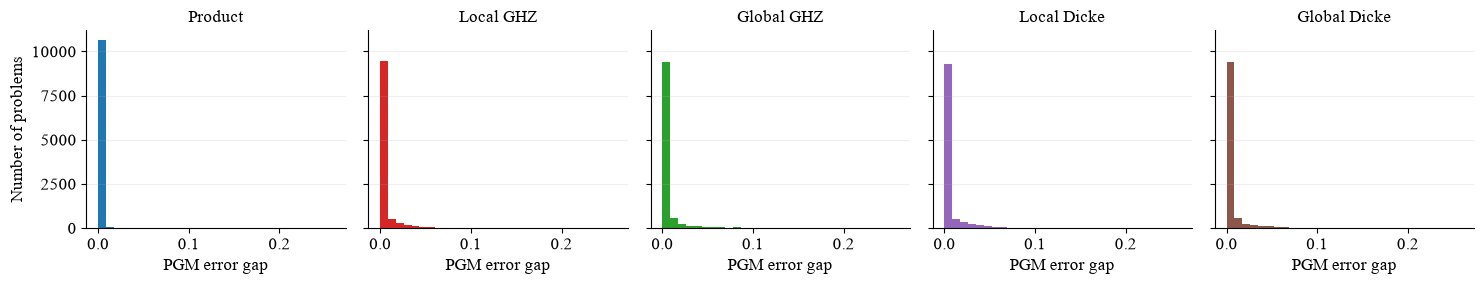

In [4]:
all_gaps = [r['gap'] for rows in diagnostics.values() for r in rows]
low, high = min(0.0, min(all_gaps)), max(ERROR_TOLERANCE, max(all_gaps))
bins = np.linspace(low, high, 31)
with plt.rc_context(STYLE):
    fig, axes = plt.subplots(1, 5, figsize=(15, 3), sharex=True, sharey=True)
    for ax, probe in zip(axes, FAMILIES):
        ax.hist([r['gap'] for r in diagnostics[probe]], bins=bins,
                color=STATE_STYLES[probe][1])
        ax.set_title(STATE_STYLES[probe][0], fontsize=12)
        ax.set_xlabel('PGM error gap')
        ax.grid(axis='y', alpha=.2)
    axes[0].set_ylabel('Number of problems')
    fig.tight_layout()
    plt.show()

Examples select the largest gap, a different allocation with equal error, and an identical allocation when available. Repeated examples are omitted.

In [5]:
examples = []
for probe, rows in diagnostics.items():
    choices = [('Largest gap', max(rows, key=lambda r: r['gap'])),
               ('Different allocation, equal error', next((r for r in rows if r['equal_error'] and not r['same_allocation']), None)),
               ('Identical allocation', next((r for r in rows if r['same_allocation']), None))]
    seen = set()
    for reason, row in choices:
        if row is None:
            continue
        e, g = row['exhaustive'], row['greedy']
        key = (e['dimension'], e['case'], e['N'])
        if key in seen:
            continue
        seen.add(key)
        examples.append([STATE_STYLES[probe][0], reason, f"{e['dimension']}D", e['case'], e['N'],
                         str(e['allocation']), str(g['allocation']),
                         f"{e['pgm_error']:.9g}", f"{g['pgm_error']:.9g}", f"{row['gap']:.6g}"])
show_table(['Input state', 'Example', 'Dimension', 'Case', 'N', 'Exhaustive allocation',
            'Greedy allocation', 'Exhaustive error', 'Greedy error', 'Gap'], examples)

| Input state | Example | Dimension | Case | N | Exhaustive allocation | Greedy allocation | Exhaustive error | Greedy error | Gap |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| Product | Largest gap | 2D | sinusoidal_k4_m5_24.csv | 2 | [1, 1, 0, 0, 0] | [1, 0, 0, 0, 1] | 0.192634656 | 0.268625428 | 0.0759908 |
| Product | Identical allocation | 1D | gaussian_k3_m3_01.csv | 2 | [1, 0, 1] | [1, 0, 1] | 0.417522759 | 0.417522759 | 0 |
| Local GHZ | Largest gap | 2D | quadratic_k4_m5_41.csv | 16 | [0, 0, 0, 5, 11] | [0, 0, 9, 6, 1] | 0.0590868626 | 0.241436867 | 0.18235 |
| Local GHZ | Identical allocation | 1D | gaussian_k3_m3_01.csv | 2 | [0, 0, 2] | [0, 0, 2] | 0.416457563 | 0.416457563 | 0 |
| Global GHZ | Largest gap | 1D | quadratic_k3_m3_27.csv | 16 | [16, 0, 0] | [6, 9, 1] | 0.347857647 | 0.607794997 | 0.259937 |
| Global GHZ | Different allocation, equal error | 1D | gaussian_k4_m4_14.csv | 5 | [2, 2, 0, 1] | [1, 2, 0, 2] | 0.50214745 | 0.502147501 | 5.1073e-08 |
| Global GHZ | Identical allocation | 1D | gaussian_k3_m3_01.csv | 2 | [0, 0, 2] | [0, 0, 2] | 0.416457563 | 0.416457563 | 0 |
| Local Dicke | Largest gap | 1D | quadratic_k3_m5_40.csv | 13 | [13, 0, 0, 0, 0] | [0, 0, 13, 0, 0] | 0.0604558871 | 0.212290658 | 0.151835 |
| Local Dicke | Identical allocation | 1D | gaussian_k3_m3_01.csv | 2 | [1, 0, 1] | [1, 0, 1] | 0.417522759 | 0.417522759 | 0 |
| Global Dicke | Largest gap | 2D | gaussian_k3_m4_20.csv | 13 | [0, 0, 13, 0] | [7, 0, 6, 0] | 0.0597296138 | 0.221359399 | 0.16163 |
| Global Dicke | Identical allocation | 1D | gaussian_k3_m3_01.csv | 2 | [1, 0, 1] | [1, 0, 1] | 0.439516595 | 0.439516595 | 0 |